# Discrete CQL trained on tree dataset

This notebook loads the CQL test trajectories and plots, per query, the cumulative trajectory cost versus the overall NDCG improvement. Points are colored by total reward: green for positive, gray for zero, and red for negative. Overlapping points are sized and labeled by the number of queries they represent.

In [33]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

CQL_PATH = Path("results/cql_test_results_after_tree.csv")
df_cql = pd.read_csv(CQL_PATH)
df_cql.head()

,query_id,query,new_query,action_name,query_length,score_spread,score_entropy,step,rank_overlap,query_drift,...,ndcg_after,recall_before,recall_after,cost,latency_ms,cumulative_cost,cumulative_latency_ms,reward,terminal,timeout
0,2082,At about what age do adults normally begin to ...,NaN,Rerank,12.0,3.117984,0.003365,0.000000,0.0,0.0,...,0.560626,0.094262,0.094262,0.3,416.111708,0.3,416.111708,-0.057558,False,False
1,2082,At about what age do adults normally begin to ...,NaN,STOP,12.0,2.465718,2.858337,0.333333,0.0,0.0,...,0.560626,0.094262,0.094262,0.0,0.000000,0.3,416.111708,0.000000,True,False
2,540006,was friedrich nietzsche an atheist,NaN,STOP,5.0,2.814436,1.360440,0.000000,0.0,0.0,...,0.307069,0.096000,0.096000,0.0,0.000000,0.0,0.000000,0.000000,True,False
3,23287,are landlords liable if someone breaks in a hu...,NaN,Rerank,10.0,2.072374,1.048962,0.000000,0.0,0.0,...,0.196033,0.041667,0.041667,0.3,435.009956,0.3,435.009956,0.160125,False,False
4,23287,are landlords liable if someone breaks in a hu...,NaN,STOP,10.0,2.855554,2.688176,0.333333,0.0,0.0,...,0.196033,0.041667,0.041667,0.0,0.000000,0.3,435.009956,0.000000,True,False


In [34]:
# Aggregate one point per query
grouped = df_cql.groupby("query_id")
per_query = pd.DataFrame({
    "cumulative_cost": grouped["cumulative_cost"].max(),
    "ndcg_improvement": grouped.apply(lambda g: g["ndcg_after"].iloc[-1] - g["ndcg_before"].iloc[0]),
    "total_reward": grouped["reward"].sum(),
}).reset_index()

def reward_category(r):
    if r > 0:
        return "positive"
    if r < 0:
        return "negative"
    return "zero"

per_query["reward_category"] = per_query["total_reward"].apply(reward_category)

print("Queries:", len(per_query))
print(per_query["reward_category"].value_counts())
per_query.head()

Queries: 50
reward_category
negative    25
zero        14
positive    11
Name: count, dtype: int64


,query_id,cumulative_cost,ndcg_improvement,total_reward,reward_category
0,2082,0.3,0.008156,-0.057558,negative
1,23287,0.3,0.117313,0.160125,positive
2,30611,0.3,0.006006,-0.060371,negative
3,112700,0.0,0.000000,0.000000,zero
4,168329,0.0,0.000000,0.000000,zero


In [35]:
# Count how many queries fall on each exact (improvement, cost, reward_category) point
point_counts = (
    per_query
    .groupby(["ndcg_improvement", "cumulative_cost", "reward_category"])
    .size()
    .reset_index(name="n_queries")
)
point_counts = point_counts.sort_values("n_queries", ascending=False).reset_index(drop=True)
point_counts.head()

,ndcg_improvement,cumulative_cost,reward_category,n_queries
0,0.000000,0.0,zero,14
1,0.000000,0.3,negative,2
2,-0.027160,0.3,negative,1
3,-0.019825,0.3,negative,1
4,-0.006731,0.3,negative,1


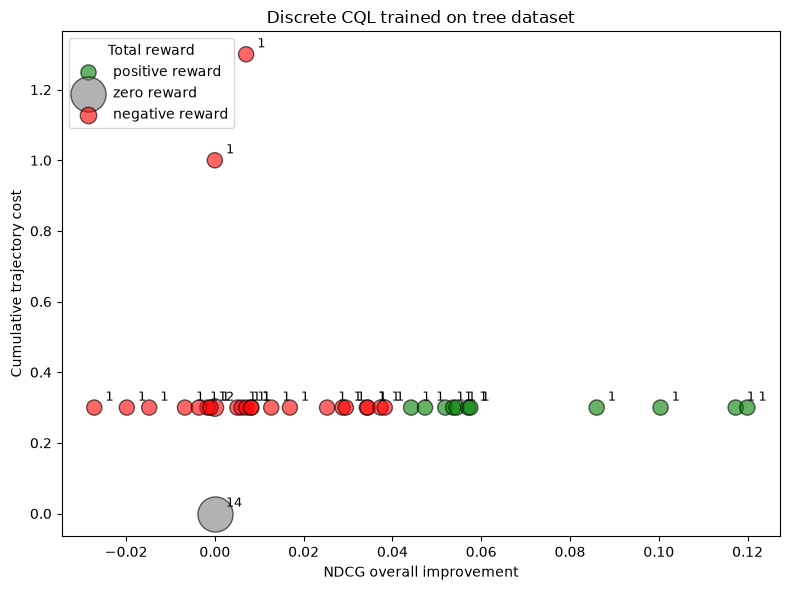

In [36]:
fig, ax = plt.subplots(figsize=(8, 6))

colors = {"positive": "green", "zero": "gray", "negative": "red"}

for category, color in colors.items():
    subset = point_counts[point_counts["reward_category"] == category]
    if subset.empty:
        continue
    ax.scatter(
        subset["ndcg_improvement"],
        subset["cumulative_cost"],
        s=80 + 40 * subset["n_queries"],
        c=color,
        alpha=0.6,
        edgecolors="black",
        label=f"{category} reward",
    )

# Label each point with its query count
for _, row in point_counts.iterrows():
    ax.annotate(
        str(int(row["n_queries"])),
        (row["ndcg_improvement"], row["cumulative_cost"]),
        textcoords="offset points",
        xytext=(8, 5),
        fontsize=9,
    )

ax.set_xlabel("NDCG overall improvement")
ax.set_ylabel("Cumulative trajectory cost")
ax.set_title("Discrete CQL trained on tree dataset")
ax.legend(title="Total reward", loc="upper left")
plt.tight_layout()
plt.show()

## CQL vs Expert: cumulative trajectory reward per query

The line plot below compares the total trajectory reward obtained by the CQL policy and the expert policy on the shared set of test queries. Query IDs are replaced by a meaningless sequential index; the goal is to compare overall performance distributions, not individual queries.

In [ ]:
EXPERT_PATH = Path("results/trajectories_expert_test_results_dev_50.csv")
df_expert = pd.read_csv(EXPERT_PATH)

# Total cumulative reward per query for each policy
cql_rewards = df_cql.groupby("query_id")["reward"].sum().rename("cql_reward")
expert_rewards = df_expert.groupby("query_id")["reward"].sum().rename("expert_reward")

# Merge and keep only queries present in both files
reward_comparison = pd.concat([cql_rewards, expert_rewards], axis=1).dropna()
reward_comparison = reward_comparison.reset_index(drop=True)
reward_comparison["query_index"] = np.arange(1, len(reward_comparison) + 1)

print("Shared queries:", len(reward_comparison))
print("Queries with different CQL/Expert reward:", (reward_comparison["cql_reward"] != reward_comparison["expert_reward"]).sum())
reward_comparison.head()

Shared queries: 0
Queries with different CQL/Expert reward: 0


,cql_reward,expert_reward,query_index


: 

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    reward_comparison["query_index"],
    reward_comparison["cql_reward"],
    marker="o",
    linestyle="-",
    linewidth=2,
    alpha=0.8,
    label="CQL",
    color="steelblue",
)
ax.plot(
    reward_comparison["query_index"],
    reward_comparison["expert_reward"],
    marker="s",
    linestyle="--",
    linewidth=2,
    alpha=0.8,
    label="Expert",
    color="darkorange",
)

ax.set_xlabel("Query (sequential index)")
ax.set_ylabel("Cumulative reward")
ax.set_title("Cumulative Trajectory Reward per Query: CQL vs Expert")
ax.set_xticks([])  # Hide x-axis tick labels; the index is not meaningful
ax.legend()
plt.tight_layout()
plt.show()